In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import os
import random
import re
from collections import Counter
from datetime import timedelta

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from joblib import load
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    KFold,
    train_test_split,
)
from sklearn.preprocessing import (
    LabelEncoder,
    OneHotEncoder,
    StandardScaler,
)
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.utils import to_categorical
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
)
from tensorflow.keras.layers import (
    Activation,
    Add,
    BatchNormalization,
    Concatenate,
    Conv1D,
    Dense,
    Dropout,
    Embedding,
    Flatten,
    GlobalAveragePooling1D,
    Input,
    MaxPooling1D,
)
from tensorflow.keras.models import Model, Sequential

# ===== Project-specific modules =====
import utils.data_models as data_models
import utils.data_preprocessing as data_preprocessing
from utils.data_integration import combine_data, read_data

In [ ]:
X_test, Y_test = load("Data/DL_Test.joblib")
X_train, Y_train = load("Data/DL_Train.joblib")

In [4]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

In [ ]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]

X_abl_train_fold = [X_train[i] for i in abl_train_idx]
Y_abl_train_fold = [Y_train[i] for i in abl_train_idx]

X_abl_val_fold = [X_train[i] for i in abl_val_idx]
Y_abl_val_fold = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))
print(len(X_test))

# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

Y_abl_train_fold =flatten(Y_abl_train_fold)
Y_abl_train_fold= Y_abl_train_fold.reshape(-1)

Y_abl_val_fold =flatten(Y_abl_val_fold)
Y_abl_val_fold= Y_abl_val_fold.reshape(-1)

Y_test_fold =flatten(Y_test)
Y_test_fold= Y_test_fold.reshape(-1)



# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)
X_abl_train_fold = flatten(X_abl_train_fold)
X_abl_val_fold = flatten(X_abl_val_fold)
X_test_fold = flatten(X_test)


print(X_train_fold.shape)
print(X_abl_train_fold.shape)
print(X_abl_val_fold.shape)
print(X_test_fold.shape)

# initiliazes buffer size and batch size 
BATCH_SIZE =  256 
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
Y_abl_train_rs = to_categorical(Y_abl_train_fold)
Y_abl_val_rs = to_categorical(Y_abl_val_fold)

# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')
Y_abl_train_weights = Y_abl_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)

X_abl_train_t = tf.convert_to_tensor(X_abl_train_fold, dtype=tf.float32)
Y_abl_train_t = tf.convert_to_tensor(Y_abl_train_rs, dtype=tf.int32)

X_abl_val_t = tf.convert_to_tensor(X_abl_val_fold, dtype=tf.float32)
Y_abl_val_t = tf.convert_to_tensor(Y_abl_val_rs, dtype=tf.int32)

X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)

# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

abl_train_ds = tf.data.Dataset.from_tensor_slices((X_abl_train_t, Y_abl_train_t)).batch(BATCH_SIZE).prefetch(1)
abl_val_ds = tf.data.Dataset.from_tensor_slices((X_abl_val_t, Y_abl_val_t)).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)
Y_abl_train_all = Y_abl_train_fold.reshape(-1)
Y_abl_val_all = Y_abl_val_fold.reshape(-1)
Y_test_all = Y_test_fold.reshape(-1)

1906
80
21
502
(12891361, 25, 1)
(630399, 25, 1)
(181224, 25, 1)
(3552429, 25, 1)


2026-05-03 12:02:01.963785: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2 Max
2026-05-03 12:02:01.963903: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2026-05-03 12:02:01.963947: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 12.48 GB
2026-05-03 12:02:01.964031: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-03 12:02:01.964080: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [6]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)

# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)
# split into temp and test (20%)
"""train_idx, abl_idx = train_test_split(temp_idx, test_size=0.05, shuffle=False, random_state=seed_value) """

abl_train_idx, abl_val_idx = train_test_split(abl_idx, test_size=0.20, shuffle=True, random_state=seed_value) 


X_train_data = [X_train[i] for i in train_idx]
X_abl_train_data = [X_train[i] for i in abl_train_idx]
X_abl_val_data = [X_train[i] for i in abl_val_idx]

Y_train_data = [Y_train[i] for i in train_idx]
Y_abl_train_data = [Y_train[i] for i in abl_train_idx]
Y_abl_val_data = [Y_train[i] for i in abl_val_idx]

print(len(train_idx))
print(len(abl_idx))
print(len(abl_train_idx))
print(len(abl_val_idx))

1906
101
80
21


In [8]:
len(Y_train_data)

1906

In [9]:
from joblib import dump, load

# Save (single file)
dump((X_train_data, Y_train_data), "Data/3Fold_Train_Data.joblib", compress=("zlib", 1))

['Data/3Fold_Train_Data.joblib']

## 1DCNN MHAL

In [25]:
from tensorflow.keras import layers
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, Activation
from tensorflow.keras.layers import GlobalAveragePooling1D, Dense, LayerNormalization, Add
from tensorflow.keras.layers import MultiHeadAttention

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

# for faster training 
gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


def build_FCN_MHAL(input_shape,  nb_classes=4,  num_heads=4, key_dim=32):

    x = Input(shape=input_shape)

    # Block 1
    conv1 = tf.keras.layers.Conv1D(128, 8,  padding='same')(x)
    conv1 = tf.keras.layers.BatchNormalization()(conv1)
    conv1 = tf.keras.layers.Activation('relu')(conv1)
    
#    drop_out = Dropout(0.2)(conv1)
    conv2 = tf.keras.layers.Conv1D(256, 5, padding='same')(conv1)
    conv2 = tf.keras.layers.BatchNormalization()(conv2)
    conv2 = tf.keras.layers.Activation('relu')(conv2)
    
#    drop_out = Dropout(0.2)(conv2)
    conv3 = tf.keras.layers.Conv1D(128, 3, padding='same')(conv2)
    conv3 = tf.keras.layers.BatchNormalization()(conv3)
    conv3 = tf.keras.layers.Activation('relu')(conv3)
    

    h = LayerNormalization()(conv3)
    attn_out = MultiHeadAttention(num_heads=num_heads, key_dim=key_dim)(h, h)
    conv3_attn = Add()([conv3, attn_out])

    full = GlobalAveragePooling1D()(conv3_attn)
    out = Dense(nb_classes, activation='softmax')(full)

    return tf.keras.Model(inputs=x, outputs=out)


Physical devices cannot be modified after being initialized


2026-04-29 21:54:36.166589: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-29 21:54:36.166640: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]


2026-04-28 22:44:15.595556: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-28 22:44:15.595591: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/10


2026-04-28 22:44:16.880760: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 114s 45ms/step - loss: 0.2632 - categorical_accuracy: 0.7236
Epoch 2/10
2463/2463 [==============================] - 112s 45ms/step - loss: 0.1822 - categorical_accuracy: 0.7924
Epoch 3/10
2463/2463 [==============================] - 114s 46ms/step - loss: 0.1714 - categorical_accuracy: 0.8022
Epoch 4/10
2463/2463 [==============================] - 115s 47ms/step - loss: 0.1670 - categorical_accuracy: 0.8053
Epoch 5/10
2463/2463 [==============================] - 118s 48ms/step - loss: 0.1655 - categorical_accuracy: 0.8071
Epoch 6/10
2463/2463 [==============================] - 116s 47ms/step - loss: 0.1612 - categorical_accuracy: 0.8106
Epoch 7/10
2463/2463 [==============================] - 117s 48ms/step - loss: 0.1587 - categorical_accuracy: 0.8126
Epoch 8/10
2463/2463 [==============================] - 119s 48ms/step - loss: 0.1572 - categorical_accuracy: 0.8144
Epoch 9/10
2463/2463 [==============================] - 119s 48ms/step - lo

2026-04-28 23:03:32.739025: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 45s 8ms/step


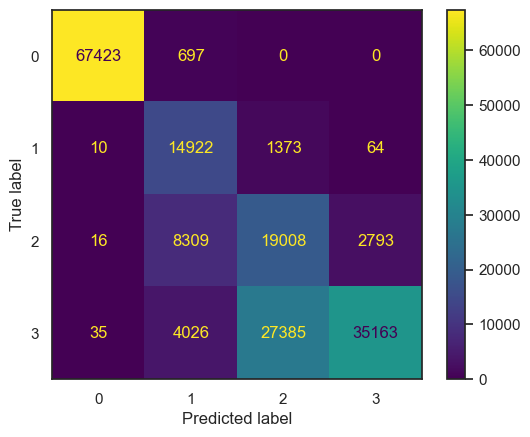

              precision    recall  f1-score   support

           0     0.9991    0.9898    0.9944     68120
           1     0.5338    0.9116    0.6733     16369
           2     0.3979    0.6310    0.4881     30126
           3     0.9249    0.5279    0.6721     66609

    accuracy                         0.7533    181224
   macro avg     0.7139    0.7651    0.7070    181224
weighted avg     0.8298    0.7533    0.7628    181224



In [14]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "MHALustomModel_4h.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )



 #                                        num_heads=4, key_dim=32 
model_fcn_mhal = build_FCN_MHAL((X_abl_train_fold.shape[1], X_abl_train_fold.shape[2]), nb_classes=4,  num_heads=4, key_dim=32) 
model_fcn_mhal.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_fcn_mhal.optimizer.learning_rate, initial_lr)
model_fcn_mhal.fit(abl_train_ds, epochs=10, verbose=1)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_fcn_mhal = model_fcn_mhal.predict(X_abl_val_t)
y_pred_fcn_mhal = np.argmax(predictions_fcn_mhal, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_fcn_mhal)
plt.show()

report_fcn_mhal = classification_report(y_true_labels, y_pred_fcn_mhal, digits=4)
print(report_fcn_mhal)

Physical devices cannot be modified after being initialized


2026-04-28 23:04:20.212397: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-28 23:04:20.212437: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-28 23:04:20.976223: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 108s 43ms/step - loss: 0.2671 - categorical_accuracy: 0.7221
Epoch 2/10
2463/2463 [==============================] - 102s 42ms/step - loss: 0.1810 - categorical_accuracy: 0.7949
Epoch 3/10
2463/2463 [==============================] - 103s 42ms/step - loss: 0.1712 - categorical_accuracy: 0.8033
Epoch 4/10
2463/2463 [==============================] - 104s 42ms/step - loss: 0.1669 - categorical_accuracy: 0.8071
Epoch 5/10
2463/2463 [==============================] - 103s 42ms/step - loss: 0.1632 - categorical_accuracy: 0.8099
Epoch 6/10
2463/2463 [==============================] - 103s 42ms/step - loss: 0.1597 - categorical_accuracy: 0.8123
Epoch 7/10
2463/2463 [==============================] - 102s 41ms/step - loss: 0.1580 - categorical_accuracy: 0.8138
Epoch 8/10
2463/2463 [==============================] - 106s 43ms/step - loss: 0.1564 - categorical_accuracy: 0.8152
Epoch 9/10
2463/2463 [==============================] - 106s 43ms/step - lo

2026-04-28 23:21:44.343295: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 43s 8ms/step


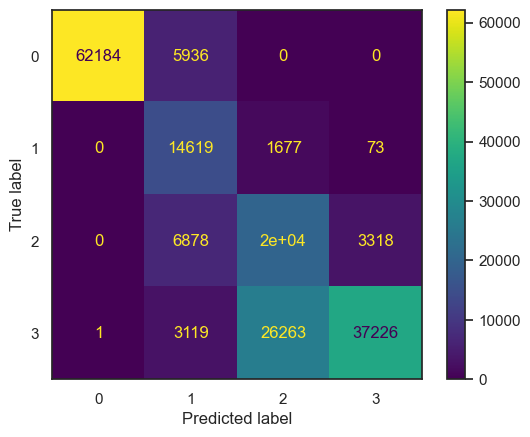

              precision    recall  f1-score   support

           0     1.0000    0.9129    0.9544     68120
           1     0.4785    0.8931    0.6231     16369
           2     0.4163    0.6616    0.5111     30126
           3     0.9165    0.5589    0.6943     66609

    accuracy                         0.7392    181224
   macro avg     0.7028    0.7566    0.6957    181224
weighted avg     0.8252    0.7392    0.7552    181224



In [15]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

tf.compat.v1.set_random_seed(seed_value)
session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)



tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "MHALustomModel_4h.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )



 #                                        num_heads=4, key_dim=32 
model_fcn_mhal = build_FCN_MHAL((X_abl_train_fold.shape[1], X_abl_train_fold.shape[2]), num_heads=8, key_dim=16) 
model_fcn_mhal.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_fcn_mhal.optimizer.learning_rate, initial_lr)
model_fcn_mhal.fit(abl_train_ds, epochs=10, verbose=1) #, validation_data=abl_val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_fcn_mhal = model_fcn_mhal.predict(X_abl_val_t)
y_pred_fcn_mhal = np.argmax(predictions_fcn_mhal, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_fcn_mhal)
plt.show()

report_fcn_mhal = classification_report(y_true_labels, y_pred_fcn_mhal, digits=4)
print(report_fcn_mhal)

Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]
Epoch 1/10


2026-04-28 23:22:31.377583: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 117s 46ms/step - loss: 0.2653 - categorical_accuracy: 0.7227
Epoch 2/10
2463/2463 [==============================] - 111s 45ms/step - loss: 0.1810 - categorical_accuracy: 0.7937
Epoch 3/10
2463/2463 [==============================] - 113s 46ms/step - loss: 0.1730 - categorical_accuracy: 0.8001
Epoch 4/10
2463/2463 [==============================] - 108s 44ms/step - loss: 0.1673 - categorical_accuracy: 0.8048
Epoch 5/10
2463/2463 [==============================] - 108s 44ms/step - loss: 0.1643 - categorical_accuracy: 0.8073
Epoch 6/10
2463/2463 [==============================] - 109s 44ms/step - loss: 0.1615 - categorical_accuracy: 0.8099
Epoch 7/10
2463/2463 [==============================] - 107s 44ms/step - loss: 0.1591 - categorical_accuracy: 0.8119
Epoch 8/10
2463/2463 [==============================] - 107s 43ms/step - loss: 0.1576 - categorical_accuracy: 0.8134
Epoch 9/10
2463/2463 [==============================] - 107s 44ms/step - lo

2026-04-28 23:40:44.547110: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 40s 7ms/step


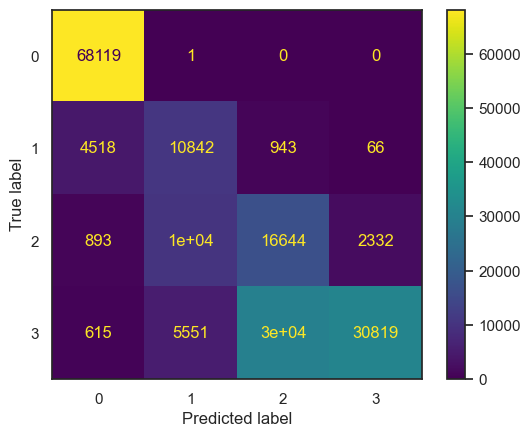

              precision    recall  f1-score   support

           0     0.9187    1.0000    0.9576     68120
           1     0.4068    0.6623    0.5040     16369
           2     0.3525    0.5525    0.4304     30126
           3     0.9278    0.4627    0.6175     66609

    accuracy                         0.6976    181224
   macro avg     0.6515    0.6694    0.6274    181224
weighted avg     0.7817    0.6976    0.7040    181224



In [16]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 


checkpoint = ModelCheckpoint(
    "MHAL_onehoaed.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )

# builds and trains the model

 #                                        num_heads=8, key_dim=16) 
model_fcn_mhal = build_FCN_MHAL((X_abl_train_fold.shape[1], X_abl_train_fold.shape[2]),  nb_classes= 4, num_heads=1, key_dim=128) 
model_fcn_mhal.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_fcn_mhal.optimizer.learning_rate, initial_lr)
model_fcn_mhal.fit(abl_train_ds, epochs=10, verbose=1)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_fcn_mhal = model_fcn_mhal.predict(X_abl_val_t)
y_pred_fcn_mhal = np.argmax(predictions_fcn_mhal, axis=1) 
y_true_labels = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels, y_pred_fcn_mhal)
plt.show()

report_fcn_mhal = classification_report(y_true_labels, y_pred_fcn_mhal, digits=4)
print(report_fcn_mhal)

In [17]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)

def build_FCN_MHAL(input_shape,  nb_classes=4,  num_heads=4, key_dim=32):

    x = Input(shape=input_shape)

    # Block 1
    conv1 = tf.keras.layers.Conv1D(128, 8,  padding='same')(x)
    conv1 = tf.keras.layers.BatchNormalization()(conv1)
    conv1 = tf.keras.layers.Activation('relu')(conv1)
    
#    drop_out = Dropout(0.2)(conv1)
    conv2 = tf.keras.layers.Conv1D(256, 5, padding='same')(conv1)
    conv2 = tf.keras.layers.BatchNormalization()(conv2)
    conv2 = tf.keras.layers.Activation('relu')(conv2)
    
#    drop_out = Dropout(0.2)(conv2)
    conv3 = tf.keras.layers.Conv1D(128, 3, padding='same')(conv2)
    conv3 = tf.keras.layers.BatchNormalization()(conv3)
    conv3 = tf.keras.layers.Activation('relu')(conv3)
    

    h = BatchNormalization()(conv3)
    attn_out = MultiHeadAttention(num_heads=num_heads, key_dim=key_dim)(h, h)
    conv3_attn = Add()([conv3, attn_out])

    full = GlobalAveragePooling1D()(conv3_attn)
    out = Dense(nb_classes, activation='softmax')(full)

    return tf.keras.Model(inputs=x, outputs=out)


Physical devices cannot be modified after being initialized


2026-04-28 23:41:27.183817: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-28 23:41:27.183843: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Physical devices cannot be modified after being initialized
Alpha weights: [0.53634673 1.9305758  1.0535101  0.47956717]


2026-04-28 23:41:27.195068: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:303] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-28 23:41:27.195088: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:269] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Epoch 1/10


2026-04-28 23:41:27.971748: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


2463/2463 [==============================] - 117s 47ms/step - loss: 0.2683 - categorical_accuracy: 0.7176
Epoch 2/10
2463/2463 [==============================] - 112s 45ms/step - loss: 0.1849 - categorical_accuracy: 0.7899
Epoch 3/10
2463/2463 [==============================] - 113s 46ms/step - loss: 0.1720 - categorical_accuracy: 0.8012
Epoch 4/10
2463/2463 [==============================] - 112s 46ms/step - loss: 0.1675 - categorical_accuracy: 0.8054
Epoch 5/10
2463/2463 [==============================] - 114s 46ms/step - loss: 0.1637 - categorical_accuracy: 0.8086
Epoch 6/10
2463/2463 [==============================] - 127s 51ms/step - loss: 0.1607 - categorical_accuracy: 0.8112
Epoch 7/10
2463/2463 [==============================] - 118s 48ms/step - loss: 0.1592 - categorical_accuracy: 0.8125
Epoch 8/10
2463/2463 [==============================] - 115s 47ms/step - loss: 0.1566 - categorical_accuracy: 0.8146
Epoch 9/10
2463/2463 [==============================] - 116s 47ms/step - lo

2026-04-29 00:00:47.124250: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


5664/5664 [==============================] - 44s 8ms/step


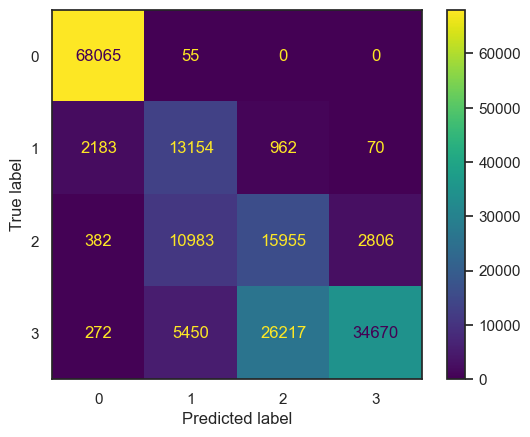

              precision    recall  f1-score   support

           0     0.9600    0.9992    0.9792     68120
           1     0.4438    0.8036    0.5718     16369
           2     0.3699    0.5296    0.4356     30126
           3     0.9234    0.5205    0.6657     66609

    accuracy                         0.7275    181224
   macro avg     0.6743    0.7132    0.6631    181224
weighted avg     0.8018    0.7275    0.7368    181224



In [18]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)


session_conf = tf.compat.v1.ConfigProto(intra_op_parallelism_threads=1, inter_op_parallelism_threads=1)
sess = tf.compat.v1.Session(graph=tf.compat.v1.get_default_graph(), config=session_conf)
tf.compat.v1.keras.backend.set_session(sess)

gpus = tf.config.experimental.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(e)



tf.keras.backend.clear_session()
initial_lr = 0.001
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=initial_lr)
#optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)
# Define the early stopping callback
early_stopping = EarlyStopping(patience=5, monitor="val_loss", mode="min", verbose=1, restore_best_weights=True)
# initialize callbacks 
reduceLR =ReduceLROnPlateau(monitor="val_loss", patience=5, verbose= 1, mode="min", factor= 0.2, min_lr = 1e-5) 

checkpoint = ModelCheckpoint(
    "MHALustomModel.weights.hdf5", monitor="val_loss",
    verbose=1, save_best_only=True, mode="min"
)

callbacks= [early_stopping, checkpoint, reduceLR]


class_counts = np.bincount(Y_abl_train_weights, minlength=4).astype(np.float32)
inv_freq = 1.0 / np.maximum(class_counts, 1)
alpha = inv_freq / np.mean(inv_freq)  # normalize mean≈1
print("Alpha weights:", alpha)

# Define focal loss with tuned alpha and gamma
focloss = tf.keras.losses.CategoricalFocalCrossentropy(
    gamma=1.5,          # focus more on hard examples
    alpha=alpha,        # per-class weights
    )



 #                                        num_heads=4, key_dim=32 
model_fcn_mhal_BN = build_FCN_MHAL((X_abl_train_fold.shape[1], X_abl_train_fold.shape[2]), nb_classes=4,  num_heads=4, key_dim=32) 
model_fcn_mhal_BN.compile(loss=focloss, optimizer=optimizer, metrics=['categorical_accuracy'])
K.set_value(model_fcn_mhal_BN.optimizer.learning_rate, initial_lr)
model_fcn_mhal_BN.fit(abl_train_ds, epochs=10, verbose=1) #, validation_data=val_ds, callbacks=callbacks)# class_weight =  class_weights)


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_fcn_mhal_BN = model_fcn_mhal_BN.predict(X_abl_val_t)
y_pred_fcn_mhal_BN = np.argmax(predictions_fcn_mhal_BN, axis=1) 
y_true_labels_BN = np.argmax(Y_abl_val_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_BN, y_pred_fcn_mhal_BN)
plt.show()

report_fcn_mhal_BN = classification_report(y_true_labels_BN, y_pred_fcn_mhal_BN, digits=4)
print(report_fcn_mhal_BN)